In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)

# Fetch the predictive maintenance dataset from the UCI repository
predictive_maintenance_dataset = fetch_ucirepo(id=601)
X = predictive_maintenance_dataset.data.features
Y = predictive_maintenance_dataset.data.targets
df = pd.concat([X, Y], axis=1)
print(df.head())
print(df.shape)
print(df.info())

# Display class distribution for the target variable
print(df['Machine failure'].value_counts(normalize=True))

# Check for missing values in the dataset
print(df.isna().sum().sum())

  Type  Air temperature  Process temperature  Rotational speed  Torque  \
0    M            298.1                308.6              1551    42.8   
1    L            298.2                308.7              1408    46.3   
2    L            298.1                308.5              1498    49.4   
3    L            298.2                308.6              1433    39.5   
4    L            298.2                308.7              1408    40.0   

   Tool wear  Machine failure  TWF  HDF  PWF  OSF  RNF  
0          0                0    0    0    0    0    0  
1          3                0    0    0    0    0    0  
2          5                0    0    0    0    0    0  
3          7                0    0    0    0    0    0  
4          9                0    0    0    0    0    0  
(10000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -

In [43]:
# Identify failure conditions and sensor readings columns in the dataset
failure_conditions = df.columns[-5:]
sensor_readings = df.columns[:-6]

print("Failure conditions columns:", failure_conditions)
print("Sensor readings columns:", sensor_readings)

Failure conditions columns: Index(['TWF', 'HDF', 'PWF', 'OSF', 'RNF'], dtype='object')
Sensor readings columns: Index(['Type', 'Air temperature', 'Process temperature', 'Rotational speed',
       'Torque', 'Tool wear'],
      dtype='object')


Drop rows where RNF = 1 and failure = 0

In [44]:
any_mode = df[failure_conditions].sum(axis=1) > 0
print(pd.crosstab(any_mode, df['Machine failure']))
bad = (df['RNF'] == 1) & (df['Machine failure'] == 0)
print(bad.sum())
print('before: ', len(df), 'dropping: ', bad.sum())
df = df[~bad].reset_index(drop=True)
print('after: ', len(df), 'failures: ', df['Machine failure'].sum())

Machine failure     0    1
row_0                     
False            9643    9
True               18  330
18
before:  10000 dropping:  18
after:  9982 failures:  339


In [45]:
# split the dataset into operational and failed machines
operational = df[df['Machine failure'] == 0]
failed = df[df['Machine failure'] == 1]

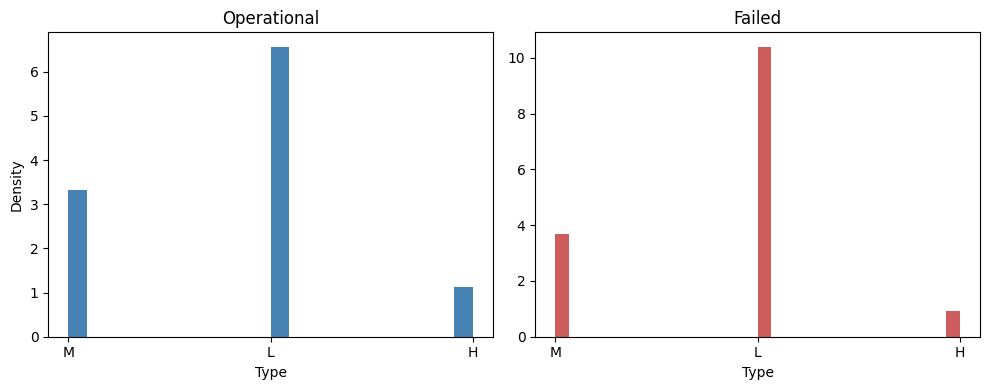

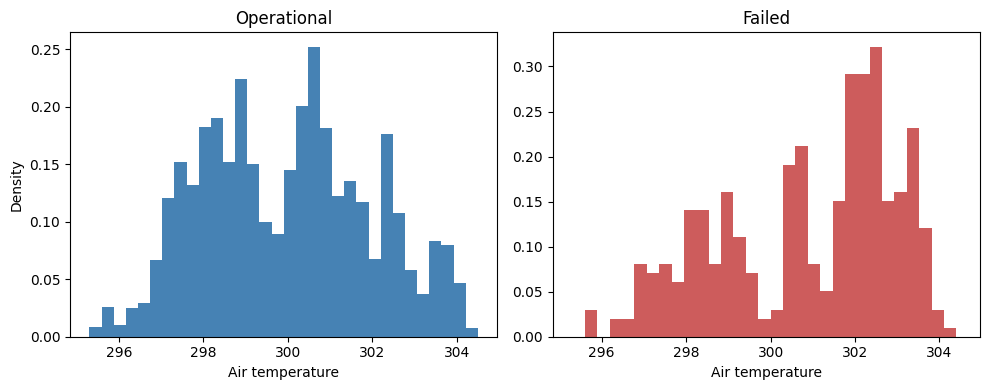

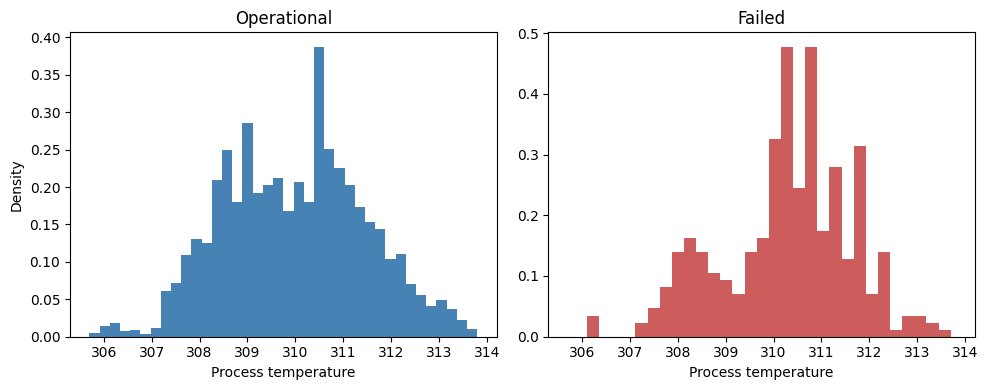

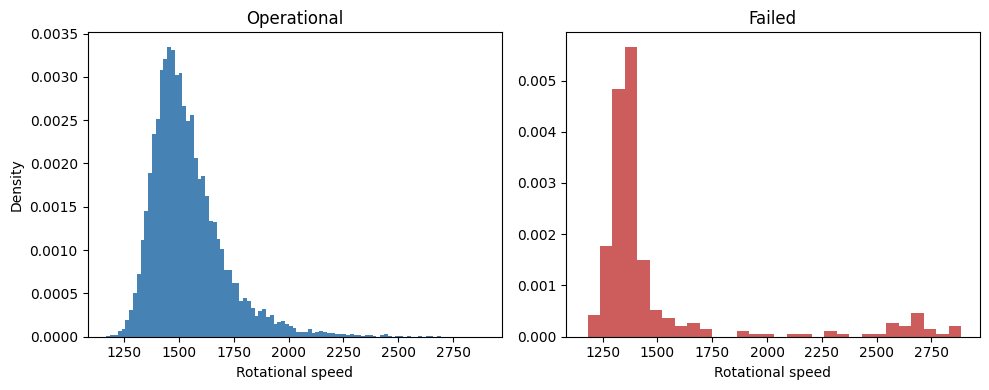

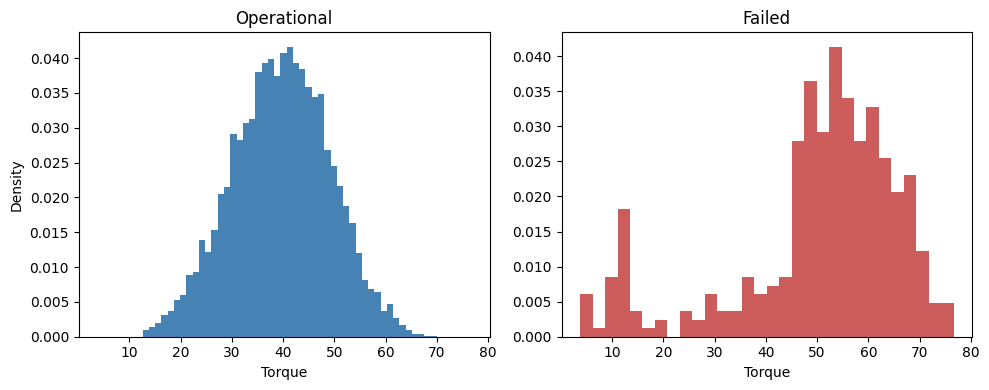

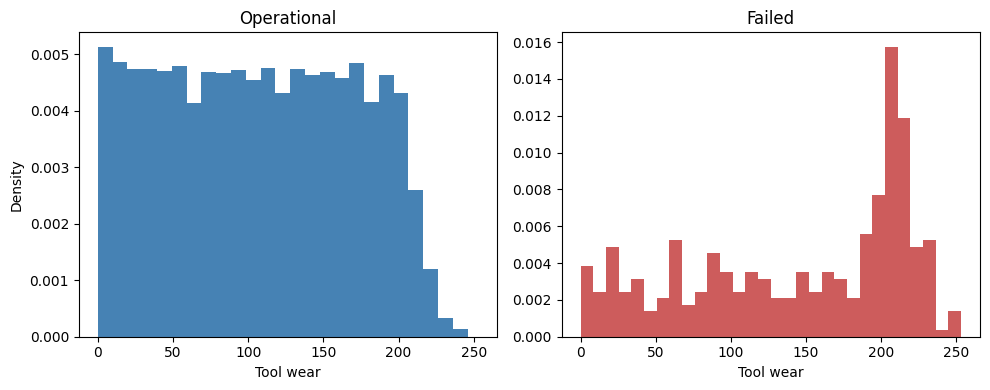

In [46]:
for sensor_reading in sensor_readings:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=False)

    axes[0].hist(operational[sensor_reading], bins='auto', density=True, color='steelblue')
    axes[0].set_title('Operational')
    axes[0].set_xlabel(sensor_reading)
    axes[0].set_ylabel('Density')

    axes[1].hist(failed[sensor_reading], bins=30, density=True, color='indianred')
    axes[1].set_title('Failed')
    axes[1].set_xlabel(sensor_reading)

    plt.tight_layout()
    plt.show()

This gives us the descriptive statistics of each pure subset of sensor readings grouped by failure conditions

In [47]:
df['num_failure_conditions'] = df[failure_conditions].sum(axis=1)

failed_condition_data = df[df['num_failure_conditions'] == 1].drop(columns=['Machine failure'])
failed_condition_data_mean_std = failed_condition_data.groupby(list(failure_conditions))[sensor_readings[1:]].agg(['mean', 'std'])
print(failed_condition_data_mean_std)

                    Air temperature           Process temperature            \
                               mean       std                mean       std   
TWF HDF PWF OSF RNF                                                           
0   0   0   1   0        299.867949  1.954050          310.051282  1.552940   
        1   0   0        300.022500  2.173487          309.961250  1.660981   
    1   0   0   0        302.560377  0.601218          310.801887  0.631398   
1   0   0   0   0        300.269048  1.941522          310.128571  1.498664   

                    Rotational speed                 Torque             \
                                mean         std       mean        std   
TWF HDF PWF OSF RNF                                                      
0   0   0   1   0        1354.243590   59.628544  56.878205   4.904216   
        1   0   0        1843.237500  646.203562  45.000000  27.771709   
    1   0   0   0        1340.707547   32.515188  52.363208   5.576077   
1 

Means for the sensor_readings in the operational group.

In [48]:
operational_sensor_readings_mean_std = operational[sensor_readings[1:]].agg(['mean', 'std'])
print(operational_sensor_readings_mean_std)

      Air temperature  Process temperature  Rotational speed     Torque  \
mean       299.972519           309.994151       1540.354869  39.622389   
std          1.990965             1.486534        167.471848   9.468446   

       Tool wear  
mean  106.669086  
std    62.936149  


We need to find how far the means of the sensor readings of the failed group deviates from the means of the sensor readings of the operational group

In [49]:
failed_means = failed_condition_data_mean_std.xs('mean', axis=1, level=1)
failed_stds = failed_condition_data_mean_std.xs('std', axis=1, level=1)

labels = failed_means.index.to_frame().idxmax(axis=1)
failed_means.index = labels
failed_stds.index = labels

operational_mean = operational_sensor_readings_mean_std.loc['mean']
operational_std = operational_sensor_readings_mean_std.loc['std']

difference_in_mean = failed_means - operational_mean
deviation_from_mean = difference_in_mean / operational_std

print(difference_in_mean.round(2))
print(deviation_from_mean.round(2))

     Air temperature  Process temperature  Rotational speed  Torque  Tool wear
OSF            -0.10                 0.06           -186.11   17.26     101.55
PWF             0.05                -0.03            302.88    5.38     -19.04
HDF             2.59                 0.81           -199.65   12.74      -5.44
TWF             0.30                 0.13             42.88   -3.63     109.55
     Air temperature  Process temperature  Rotational speed  Torque  Tool wear
OSF            -0.05                 0.04             -1.11    1.82       1.61
PWF             0.03                -0.02              1.81    0.57      -0.30
HDF             1.30                 0.54             -1.19    1.35      -0.09
TWF             0.15                 0.09              0.26   -0.38       1.74


Next we split our data into training/testing and discretize our variables to get them ready for learning structures. For air temperature, process temperature, and torque, we cut them into low/mid/high bins at +/- 1 standard deviation from their mean. The additional variable information on the UCI Machine Learning repo already documented the failure thresholds for tool wear (200 to 240 mins) and rotational speed (1380 rpm).

In [50]:
from sklearn.model_selection import train_test_split

cuts = {
    'Air temperature':     [-np.inf, 298, 302, np.inf],
    'Process temperature': [-np.inf, 308, 312, np.inf],
    'Torque':              [-np.inf, 30, 50, np.inf],
    'Tool wear':           [-np.inf, 200, np.inf],
    'Rotational speed':    [-np.inf, 1380, np.inf],
}

discretized = df[['Type']].copy()
for col, edges in cuts.items():
    if (col == 'Rotational speed') or (col == 'Tool wear'):
        discretized[col] = pd.cut(df[col], bins=edges, right=False, labels=['low', 'high'])
    else:
        discretized[col] = pd.cut(df[col], bins=edges, right=False, labels=['low', 'mid', 'high'])
discretized['Machine failure'] = df['Machine failure']
print(discretized.apply(lambda s: s.value_counts()).T)

train_df, test_df = train_test_split(
    discretized, test_size=0.3,
    stratify=discretized['Machine failure'],
    random_state=42)

                         H       L       M    high     low     mid       0  \
Type                 999.0  5988.0  2995.0     NaN     NaN     NaN     NaN   
Air temperature        NaN     NaN     NaN  1987.0  1762.0  6233.0     NaN   
Process temperature    NaN     NaN     NaN   947.0   813.0  8222.0     NaN   
Torque                 NaN     NaN     NaN  1567.0  1574.0  6841.0     NaN   
Tool wear              NaN     NaN     NaN   800.0  9182.0     NaN     NaN   
Rotational speed       NaN     NaN     NaN  8625.0  1357.0     NaN     NaN   
Machine failure        NaN     NaN     NaN     NaN     NaN     NaN  9643.0   

                         1  
Type                   NaN  
Air temperature        NaN  
Process temperature    NaN  
Torque                 NaN  
Tool wear              NaN  
Rotational speed       NaN  
Machine failure      339.0  


Figure out what learning algorithm to use

In [51]:
from pgmpy.causal_discovery import PC, HillClimbSearch, ExpertKnowledge
from pgmpy.structure_score import BIC

expert = ExpertKnowledge(
    temporal_order=[
        ['Type'],
        ['Air temperature', 'Process temperature', 'Torque', 'Tool wear', 'Rotational speed'],
        ['Machine failure']
    ]
)

hc = HillClimbSearch(scoring_method=BIC(train_df), expert_knowledge=expert, return_type='dag', show_progress=False).fit(train_df)
pc = PC(ci_test='chi_square', return_type='dag', show_progress=False).fit(train_df)

print(hc.causal_graph_.number_of_edges(), sorted(hc.causal_graph_.edges()))
print(pc.causal_graph_.number_of_edges(), sorted(pc.causal_graph_.edges()))

print(hc.score(X=test_df, metric='correlation_score'))
print(pc.score(X=test_df, metric='correlation_score'))

5 [('Air temperature', 'Machine failure'), ('Air temperature', 'Process temperature'), ('Rotational speed', 'Machine failure'), ('Tool wear', 'Machine failure'), ('Torque', 'Rotational speed')]
6 [('Air temperature', 'Machine failure'), ('Process temperature', 'Air temperature'), ('Rotational speed', 'Machine failure'), ('Tool wear', 'Machine failure'), ('Torque', 'Machine failure'), ('Torque', 'Rotational speed')]
0.9285714285714286
0.9285714285714286


Fit model to hc

In [52]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

hc_model = DiscreteBayesianNetwork(hc.causal_graph_.edges())
hc_model.add_nodes_from(train_df.columns)

hc_model.fit(train_df, estimator=DiscreteBayesianEstimator(prior_type='BDeu'))

print(hc_model.check_model())
cpd = hc_model.get_cpds('Machine failure')
print(cpd.to_dataframe().round(2).to_string())

True
Machine failure                                0     1
Air temperature Rotational speed Tool wear            
high            high             high       0.87  0.13
                                 low        0.99  0.01
                low              high       0.28  0.72
                                 low        0.60  0.40
low             high             high       0.91  0.09
                                 low        1.00  0.00
                low              high       0.40  0.60
                                 low        0.95  0.05
mid             high             high       0.90  0.10
                                 low        0.99  0.01
                low              high       0.60  0.40
                                 low        0.94  0.06


Fit model to pc

In [53]:
pc_model = DiscreteBayesianNetwork(pc.causal_graph_.edges())
pc_model.add_nodes_from(train_df.columns)
pc_model.fit(train_df, estimator=DiscreteBayesianEstimator(prior_type='BDeu'))
print(pc_model.check_model())
cpd = pc_model.get_cpds('Machine failure')
print(cpd.to_dataframe().round(2).to_string())

True
Machine failure                                       0     1
Air temperature Rotational speed Tool wear Torque            
high            high             high      high    0.43  0.57
                                           low     1.00  0.00
                                           mid     0.88  0.12
                                 low       high    0.98  0.02
                                           low     0.98  0.02
                                           mid     1.00  0.00
                low              high      high    0.23  0.77
                                           low     0.50  0.50
                                           mid     0.40  0.60
                                 low       high    0.61  0.39
                                           low     0.50  0.50
                                           mid     0.57  0.43
low             high             high      high    0.79  0.21
                                           low     0.91  0.09
   

Test both models

In [54]:
from sklearn.metrics import log_loss, average_precision_score

y_test = test_df['Machine failure']
X_test = test_df.drop(columns=['Machine failure'])

for name, m in [('HC', hc_model), ('PC', pc_model)]:
    prediction = m.predict_probability(X_test)['Machine failure_1']
    print(name, 'log loss: ', round(log_loss(y_test, prediction), 2), 'PR-AUC: ', round(average_precision_score(y_test, prediction), 2))

print('no-skill PR-AUC: ', round(y_test.mean(), 2))

HC log loss:  0.1 PR-AUC:  0.31
PC log loss:  0.09 PR-AUC:  0.38
no-skill PR-AUC:  0.03


In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, average_precision_score

non_discrete_sensor_readings = sensor_readings[:1]

X_all = pd.get_dummies(df[sensor_readings], columns=['Type'], drop_first=True, dtype=float)

X_lr_train = X_all.loc[train_df.index]
X_lr_test = X_all.loc[test_df.index]
y_lr_train = df.loc[train_df.index, 'Machine failure']
y_lr_test = df.loc[test_df.index, 'Machine failure']

log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_reg.fit(X_lr_train, y_lr_train)

p_lr = log_reg.predict_proba(X_lr_test)[:, 1]
print('LR log loss: ', round(log_loss(y_lr_test, p_lr), 2))
print('PR-AUC: ', round(average_precision_score(y_lr_test, p_lr), 2))

LR log loss:  0.09
PR-AUC:  0.5


Logistic Regression beats the Bayesian models

In [ ]:
import statsmodels.formula.api as smf

data_for_logit = df.loc[train_df.index].rename(columns=lambda c: c.replace(' ', '_'))
model = smf.logit('Machine_failure ~ Air_temperature + Process_temperature + Torque + Tool_wear + Rotational_speed', data=data_for_logit)
result = model.fit()
print(result.summary())


Optimization terminated successfully.
         Current function value: 0.098519
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:        Machine_failure   No. Observations:                 6987
Model:                          Logit   Df Residuals:                     6981
Method:                           MLE   Df Model:                            5
Date:                Wed, 14 Oct 2026   Pseudo R-squ.:                  0.3349
Time:                        15:18:18   Log-Likelihood:                -688.35
converged:                       True   LL-Null:                       -1034.9
Covariance Type:            nonrobust   LLR p-value:                1.554e-147
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept             -35.7011     17.279     -2.066      0.039     -69.567      -1.835
Ai